In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

/Users/utsavsingh/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Set style
sns.set(style="whitegrid")
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

In [3]:
# Load dataset
df = pd.read_csv('UberDataset.csv')

# Show first few rows
print(df.head())


         START_DATE          END_DATE  CATEGORY        START             STOP  \
0  01-01-2016 21:11  01-01-2016 21:17  Business  Fort Pierce      Fort Pierce   
1  01-02-2016 01:25  01-02-2016 01:37  Business  Fort Pierce      Fort Pierce   
2  01-02-2016 20:25  01-02-2016 20:38  Business  Fort Pierce      Fort Pierce   
3  01-05-2016 17:31  01-05-2016 17:45  Business  Fort Pierce      Fort Pierce   
4  01-06-2016 14:42  01-06-2016 15:49  Business  Fort Pierce  West Palm Beach   

   MILES          PURPOSE  
0    5.1   Meal/Entertain  
1    5.0              NaN  
2    4.8  Errand/Supplies  
3    4.7          Meeting  
4   63.7   Customer Visit  


In [4]:
# Display column names
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['START_DATE', 'END_DATE', 'CATEGORY', 'START', 'STOP', 'MILES',
       'PURPOSE'],
      dtype='object')


In [5]:
# Dataset structure
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1156 entries, 0 to 1155
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   START_DATE  1156 non-null   object 
 1   END_DATE    1155 non-null   object 
 2   CATEGORY    1155 non-null   object 
 3   START       1155 non-null   object 
 4   STOP        1155 non-null   object 
 5   MILES       1156 non-null   float64
 6   PURPOSE     653 non-null    object 
dtypes: float64(1), object(6)
memory usage: 63.3+ KB
None


In [6]:
# Check for nulls
print(df.isnull().sum())


START_DATE      0
END_DATE        1
CATEGORY        1
START           1
STOP            1
MILES           0
PURPOSE       503
dtype: int64


In [7]:
# Check unique values per column
print(df.nunique())

START_DATE    1155
END_DATE      1154
CATEGORY         2
START          177
STOP           188
MILES          257
PURPOSE         10
dtype: int64


In [8]:
# Fill missing values
df['PURPOSE'].fillna("Unknown", inplace=True)
df.dropna(subset=['CATEGORY', 'MILES'], inplace=True)

/var/folders/cq/xv6rlcfx5j97fr5c2mrwq9nw0000gn/T/ipykernel_86048/534943348.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['PURPOSE'].fillna("Unknown", inplace=True)


In [9]:
# Drop rows with missing CATEGORY or MILES (important fields)
top_purposes = df['PURPOSE'].value_counts().head(5)

In [10]:
# Top 5 most frequent Trip Purposes
top_purposes = df['PURPOSE'].value_counts().head(5)
print("Top 5 Trip Purposes:")
print(top_purposes)

Top 5 Trip Purposes:
PURPOSE
Unknown            502
Meeting            187
Meal/Entertain     160
Errand/Supplies    128
Customer Visit     101
Name: count, dtype: int64


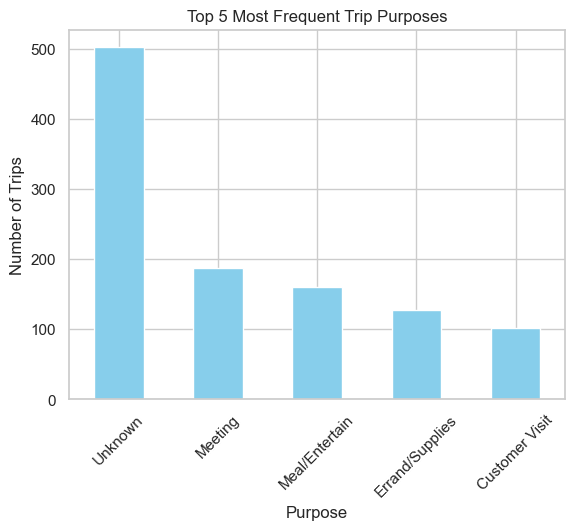

In [11]:
top_purposes.plot(kind='bar', color='skyblue')
plt.title("Top 5 Most Frequent Trip Purposes")
plt.xlabel("Purpose")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.show()

In [34]:
# Total business and personal rides
print("Count of Business vs Personal Rides:")
print(df['CATEGORY'].value_counts())


Count of Business vs Personal Rides:
CATEGORY
Business    1079
Personal      77
Name: count, dtype: int64


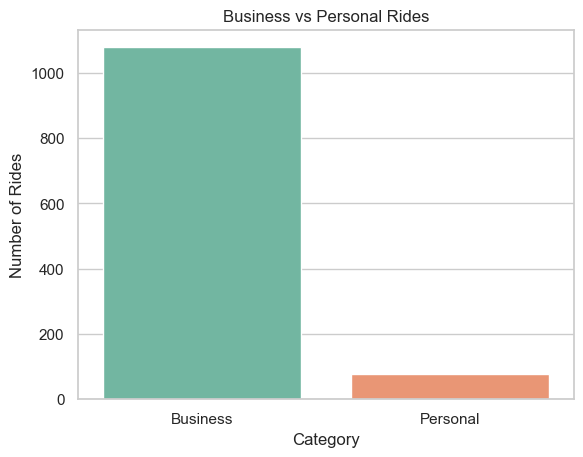

In [35]:
# Count of each CATEGORY
sns.countplot(data=df, x='CATEGORY', palette='Set2')
plt.title("Business vs Personal Rides")
plt.xlabel("Category")
plt.ylabel("Number of Rides")
plt.show()

In [36]:
# Classification Task Force(Binary Classification)
print("Original data shape:", df.shape)

# Drop rows where key columns are missing
df_cleaned = df.dropna(subset=['CATEGORY', 'PURPOSE', 'MILES'])

print("Cleaned data shape:", df_cleaned.shape)
print(df_cleaned[['CATEGORY', 'PURPOSE', 'MILES']].head(10))

Original data shape: (1156, 7)
Cleaned data shape: (1156, 7)
   CATEGORY          PURPOSE  MILES
0  Business   Meal/Entertain    5.1
1  Business   Meal/Entertain    5.0
2  Business  Errand/Supplies    4.8
3  Business          Meeting    4.7
4  Business   Customer Visit   63.7
5  Business   Meal/Entertain    4.3
6  Business          Meeting    7.1
7  Business          Meeting    0.8
8  Business          Meeting    8.3
9  Business   Customer Visit   16.5
